## Lifestyle and Obesity Analysis

In this project, I am performing an end-to-end data analytics workflow on a lifestyle and obesity dataset using Python in Jupyter Notebook. The objective is to explore how eating habits, physical activity, family history, and other lifestyle factors are associated with obesity levels.

before starting any data analysis project, I first import the required Python libraries. These libraries provide the tools needed for data handling, numerical computation, and visualization.

Pandas is used to load and manipulate tabular data.

NumPy is used for numerical operations.

Matplotlib and Seaborn are used to create visualizations.

Importing all libraries at the beginning ensures consistency and avoids repetition later in the notebook.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

The dataset file Dataset.csv is stored in the same folder as this Jupyter Notebook.
Because of this, I can load the dataset directly by providing only the file name, without using an absolute file path.

I load the dataset into a Pandas DataFrame named df, which will be the main object used for all further analysis.

In [2]:
df = pd.read_csv("Dataset.csv")

After loading the dataset, it is important to verify that the data has been read correctly.
I display the first five rows of the dataset to visually confirm the structure and values.

In [3]:
df.head()

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


Before proceeding with data preprocessing, I display all the column names in the dataset. This helps me understand the available features and identify column names that may need to be renamed for better readability and consistency throughout the analysis.

In [4]:
df.columns

Index(['Gender', 'Age', 'Height', 'Weight', 'family_history_with_overweight',
       'FAVC', 'FCVC', 'NCP', 'CAEC', 'SMOKE', 'CH2O', 'SCC', 'FAF', 'TUE',
       'CALC', 'MTRANS', 'NObeyesdad'],
      dtype='str')

The original dataset contains several abbreviated column names that may be difficult to understand during analysis. In this step, I rename these columns to more descriptive and meaningful names while preserving their original meanings. This improves code readability and makes the dataset easier to interpret during preprocessing and exploratory data analysis.

FAVC	Frequent consumption of high-calorie food,
FCVC	Frequency of vegetable consumption,
NCP	    Number of main meals per day,
CAEC	Consumption of food between meals,
CH2O	Daily water consumption,
SCC	    Whether the individual monitors their calorie consumption,
FAF	    Frequency of physical activity,
TUE	    Time spent using technological devices,
CALC	Consumption frequency of alcohol,
MTRANS	Main mode of transportation,
NObeyesdad	Obesity level classification (the target category)

In [5]:
df.rename(columns={
    "FAVC" : "High_Calorie_Food",
    "FCVC" : "Vegetable_Consumption",
    "NCP" : "Main_Meals_Per_Day",
    "CAEC" : "Between_Meal_Food",
    "CH2O" : "Water_Consumption",
    "SCC" : "Calorie_Monitoring",
    "FAF" : "Physical_Activity",
    "TUE" : "Technology_Usage",
    "CALC" : "Alcohol_Consumption",
    "MTRANS" : "Transportation_Mode",
    "NObeyesdad" : "Obesity_level"
}, inplace=True)
    

In [6]:
df.columns

Index(['Gender', 'Age', 'Height', 'Weight', 'family_history_with_overweight',
       'High_Calorie_Food', 'Vegetable_Consumption', 'Main_Meals_Per_Day',
       'Between_Meal_Food', 'SMOKE', 'Water_Consumption', 'Calorie_Monitoring',
       'Physical_Activity', 'Technology_Usage', 'Alcohol_Consumption',
       'Transportation_Mode', 'Obesity_level'],
      dtype='str')

After loading the dataset and renaming the columns, I check its dimensions using the shape attribute in Pandas. This returns the total number of rows and columns in the dataset. 

In [7]:
df.shape

(2111, 17)

This means 2,111 rows and 17 columns for the original dataset, before removing any duplicates.

### Understanding Dataset Information

In this step, I use the `info()` method to examine the dataset's structure. It displays the column names, number of non-null values, data types, and memory usage. This helps identify columns that may need data type conversion or missing-value handling during preprocessing.

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Gender                          2111 non-null   str    
 1   Age                             2111 non-null   float64
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   family_history_with_overweight  2111 non-null   str    
 5   High_Calorie_Food               2111 non-null   str    
 6   Vegetable_Consumption           2111 non-null   float64
 7   Main_Meals_Per_Day              2111 non-null   float64
 8   Between_Meal_Food               2111 non-null   str    
 9   SMOKE                           2111 non-null   str    
 10  Water_Consumption               2111 non-null   float64
 11  Calorie_Monitoring              2111 non-null   str    
 12  Physical_Activity               2111 non-null

### Checking for Missing Values

In this step, I check each column for missing values using the `isnull()` and `sum()` methods. This helps confirm whether any records contain empty or missing entries that may require treatment before analysis.

In [9]:
df.isnull().sum()

Gender                            0
Age                               0
Height                            0
Weight                            0
family_history_with_overweight    0
High_Calorie_Food                 0
Vegetable_Consumption             0
Main_Meals_Per_Day                0
Between_Meal_Food                 0
SMOKE                             0
Water_Consumption                 0
Calorie_Monitoring                0
Physical_Activity                 0
Technology_Usage                  0
Alcohol_Consumption               0
Transportation_Mode               0
Obesity_level                     0
dtype: int64

### Checking for Duplicate Records

In this step, I check whether the dataset contains duplicate rows using the `duplicated()` method. Duplicate records can affect the accuracy of analysis, so identifying them is an important part of data preprocessing.

In [10]:
df.duplicated().sum()

np.int64(24)

### Removing Duplicate Records

The duplicate check identified 24 duplicate rows in the dataset. In this step, I use the `drop_duplicates()` method to remove duplicate records while keeping the first occurrence of each row. This helps improve data quality and prevents duplicate records from affecting the analysis.

In [11]:
df.drop_duplicates(inplace = True)

### Verifying Duplicate Removal

After removing duplicates, I check the dataset again to confirm that no duplicate rows remain and to determine the updated number of records.

In [12]:
print("Dataset shape after removing duplicates:", df.shape)
print("Remaining duplicate rows:", df.duplicated().sum())

Dataset shape after removing duplicates: (2087, 17)
Remaining duplicate rows: 0


### Checking Data Types

In this step, I examine the data type of each column using the `dtypes` attribute. This helps identify numerical and categorical columns and determine whether any data type conversions are required during preprocessing.

In [13]:
df.dtypes

Gender                                str
Age                               float64
Height                            float64
Weight                            float64
family_history_with_overweight        str
High_Calorie_Food                     str
Vegetable_Consumption             float64
Main_Meals_Per_Day                float64
Between_Meal_Food                     str
SMOKE                                 str
Water_Consumption                 float64
Calorie_Monitoring                    str
Physical_Activity                 float64
Technology_Usage                  float64
Alcohol_Consumption                   str
Transportation_Mode                   str
Obesity_level                         str
dtype: object

### Reviewing Numerical Data

In this step, I use the `describe()` method to generate descriptive statistics for numerical columns. These statistics help me understand the distribution and range of values and identify potentially unusual values that may require further investigation during data preprocessing.

In [14]:
df.describe()

,Age,Height,Weight,Vegetable_Consumption,Main_Meals_Per_Day,Water_Consumption,Physical_Activity,Technology_Usage
count,2087.000000,2087.000000,2087.000000,2087.000000,2087.000000,2087.000000,2087.000000,2087.000000
mean,24.353090,1.702674,86.858730,2.421466,2.701179,2.004749,1.012812,0.663035
std,6.368801,0.093186,26.190847,0.534737,0.764614,0.608284,0.853475,0.608153
min,14.000000,1.450000,39.000000,1.000000,1.000000,1.000000,0.000000,0.000000
25%,19.915937,1.630178,66.000000,2.000000,2.697467,1.590922,0.124505,0.000000
50%,22.847618,1.701584,83.101100,2.396265,3.000000,2.000000,1.000000,0.630866
75%,26.000000,1.769491,108.015907,3.000000,3.000000,2.466193,1.678102,1.000000
max,61.000000,1.980000,173.000000,3.000000,4.000000,3.000000,3.000000,2.000000


### Checking Categorical Values

In this step, I examine the unique values present in categorical columns. This helps identify inconsistent category labels, unexpected values, or spelling differences that could affect the accuracy of the analysis. The results will help determine whether any standardization is required.


In [15]:
catogorical_columns = df.select_dtypes(include="str").columns

for column in catogorical_columns:
    print(f"\n{column}:")
    print(df[column].unique())


Gender:
<StringArray>
['Female', 'Male']
Length: 2, dtype: str

family_history_with_overweight:
<StringArray>
['yes', 'no']
Length: 2, dtype: str

High_Calorie_Food:
<StringArray>
['no', 'yes']
Length: 2, dtype: str

Between_Meal_Food:
<StringArray>
['Sometimes', 'Frequently', 'Always', 'no']
Length: 4, dtype: str

SMOKE:
<StringArray>
['no', 'yes']
Length: 2, dtype: str

Calorie_Monitoring:
<StringArray>
['no', 'yes']
Length: 2, dtype: str

Alcohol_Consumption:
<StringArray>
['no', 'Sometimes', 'Frequently', 'Always']
Length: 4, dtype: str

Transportation_Mode:
<StringArray>
['Public_Transportation', 'Walking', 'Automobile', 'Motorbike', 'Bike']
Length: 5, dtype: str

Obesity_level:
<StringArray>
[      'Normal_Weight',  'Overweight_Level_I', 'Overweight_Level_II',
      'Obesity_Type_I', 'Insufficient_Weight',     'Obesity_Type_II',
    'Obesity_Type_III']
Length: 7, dtype: str


### Cleaning Whitespace 

In this step, I remove any unnecessary leading or trailing whitespace from categorical values. This ensures that identical categories are not treated as different values because of accidental spaces. I will then verify that the categorical values remain consistent.

In [16]:
catogorical_columns = df.select_dtypes(include="str").columns

for column in catogorical_columns:
    df[column] = df[column].str.strip()

### Verifying Whitespace Cleaning

After cleaning, I inspect the unique values in the categorical columns again to confirm that the categories remain consistent.

In [17]:
for column in catogorical_columns:
    print(f"{column}:{df[column].unique()}")

Gender:<StringArray>
['Female', 'Male']
Length: 2, dtype: str
family_history_with_overweight:<StringArray>
['yes', 'no']
Length: 2, dtype: str
High_Calorie_Food:<StringArray>
['no', 'yes']
Length: 2, dtype: str
Between_Meal_Food:<StringArray>
['Sometimes', 'Frequently', 'Always', 'no']
Length: 4, dtype: str
SMOKE:<StringArray>
['no', 'yes']
Length: 2, dtype: str
Calorie_Monitoring:<StringArray>
['no', 'yes']
Length: 2, dtype: str
Alcohol_Consumption:<StringArray>
['no', 'Sometimes', 'Frequently', 'Always']
Length: 4, dtype: str
Transportation_Mode:<StringArray>
['Public_Transportation', 'Walking', 'Automobile', 'Motorbike', 'Bike']
Length: 5, dtype: str
Obesity_level:<StringArray>
[      'Normal_Weight',  'Overweight_Level_I', 'Overweight_Level_II',
      'Obesity_Type_I', 'Insufficient_Weight',     'Obesity_Type_II',
    'Obesity_Type_III']
Length: 7, dtype: str


### Creating a BMI Column

In this step, I create a new column named `BMI` using the existing `Weight` and `Height` columns. BMI is calculated by dividing weight in kilograms by the square of height in metres. This derived feature will be useful for exploring relationships between body measurements and obesity-level categories during the later EDA stage. The original columns are retained.

In [18]:
df['BMI'] = df["Weight"]/(df["Height"]**2)

### Verifying the BMI Column

I display the height, weight, and newly calculated BMI values for the first five records to verify that the calculation was performed correctly.

In [19]:
df[['Height' , 'Weight' , 'BMI']].head()

,Height,Weight,BMI
0,1.62,64.0,24.386526
1,1.52,56.0,24.238227
2,1.80,77.0,23.765432
3,1.80,87.0,26.851852
4,1.78,89.8,28.342381


### Creating Age Groups

In this step, I create a new column named `Age_Group` by grouping the `Age` values into meaningful age ranges. This derived feature will make age-group comparisons easier during the later exploratory data analysis. The original `Age` column is retained.

In [20]:
bins = [0,18,26,36,46,56, float("inf")]
labels = ["Under 18","18 - 25","26 - 35","36 - 45","46 - 55","56+"]

df["Age_Group"] = pd.cut(df["Age"],bins = bins,labels = labels,right=False)

### Verifying Age Groups

I display the original age and the newly created age-group column for the first five records to verify that the age ranges have been assigned correctly.

In [21]:
df[["Age","Age_Group"]].head()

,Age,Age_Group
0,21.0,18 - 25
1,21.0,18 - 25
2,23.0,18 - 25
3,27.0,26 - 35
4,22.0,18 - 25


### Final Data Quality Check

In this step, I perform a final quality check on the preprocessed dataset. I check for missing values, duplicate rows, the dataset dimensions, and the data types of all columns to ensure the dataset is ready for further analysis.

In [22]:
print("Dataset shape:", df.shape)

Dataset shape: (2087, 19)


In [23]:
print("\nMissing values in each column:")
print(df.isnull().sum())


Missing values in each column:
Gender                            0
Age                               0
Height                            0
Weight                            0
family_history_with_overweight    0
High_Calorie_Food                 0
Vegetable_Consumption             0
Main_Meals_Per_Day                0
Between_Meal_Food                 0
SMOKE                             0
Water_Consumption                 0
Calorie_Monitoring                0
Physical_Activity                 0
Technology_Usage                  0
Alcohol_Consumption               0
Transportation_Mode               0
Obesity_level                     0
BMI                               0
Age_Group                         0
dtype: int64


In [24]:
print("\nTotal missing values:", df.isnull().sum().sum())


Total missing values: 0


In [25]:
print("\nDuplicate rows:", df.duplicated().sum())


Duplicate rows: 0


In [26]:
print("\nColumn data types:")
print(df.dtypes)


Column data types:
Gender                                 str
Age                                float64
Height                             float64
Weight                             float64
family_history_with_overweight         str
High_Calorie_Food                      str
Vegetable_Consumption              float64
Main_Meals_Per_Day                 float64
Between_Meal_Food                      str
SMOKE                                  str
Water_Consumption                  float64
Calorie_Monitoring                     str
Physical_Activity                  float64
Technology_Usage                   float64
Alcohol_Consumption                    str
Transportation_Mode                    str
Obesity_level                          str
BMI                                float64
Age_Group                         category
dtype: object


### Reviewing the Final Dataset

I display the first five records and the descriptive statistics of the preprocessed dataset to review the final structure and numerical columns.

In [27]:
display(df.head())

display(df.describe())

,Gender,Age,Height,Weight,family_history_with_overweight,High_Calorie_Food,Vegetable_Consumption,Main_Meals_Per_Day,Between_Meal_Food,SMOKE,Water_Consumption,Calorie_Monitoring,Physical_Activity,Technology_Usage,Alcohol_Consumption,Transportation_Mode,Obesity_level,BMI,Age_Group
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight,24.386526,18 - 25
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight,24.238227,18 - 25
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight,23.765432,18 - 25
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I,26.851852,26 - 35
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II,28.342381,18 - 25


,Age,Height,Weight,Vegetable_Consumption,Main_Meals_Per_Day,Water_Consumption,Physical_Activity,Technology_Usage,BMI
count,2087.000000,2087.000000,2087.000000,2087.000000,2087.000000,2087.000000,2087.000000,2087.000000,2087.000000
mean,24.353090,1.702674,86.858730,2.421466,2.701179,2.004749,1.012812,0.663035,29.765758
std,6.368801,0.093186,26.190847,0.534737,0.764614,0.608284,0.853475,0.608153,8.024934
min,14.000000,1.450000,39.000000,1.000000,1.000000,1.000000,0.000000,0.000000,12.998685
25%,19.915937,1.630178,66.000000,2.000000,2.697467,1.590922,0.124505,0.000000,24.368897
50%,22.847618,1.701584,83.101100,2.396265,3.000000,2.000000,1.000000,0.630866,28.896224
75%,26.000000,1.769491,108.015907,3.000000,3.000000,2.466193,1.678102,1.000000,36.095538
max,61.000000,1.980000,173.000000,3.000000,4.000000,3.000000,3.000000,2.000000,50.811753


### Frequency Distribution of Categorical Variables

In this step, I examine the frequency distribution of categorical variables to understand the number of records in each category. This helps identify the most common gender, obesity level, eating habits, and transportation mode in the dataset.

In [28]:
categorical_columns = df.select_dtypes(include="str").columns

for column in categorical_columns:
    print(f"\nFrequency distribution of {column}:")
    print(df[column].value_counts())


Frequency distribution of Gender:
Gender
Male      1052
Female    1035
Name: count, dtype: int64

Frequency distribution of family_history_with_overweight:
family_history_with_overweight
yes    1722
no      365
Name: count, dtype: int64

Frequency distribution of High_Calorie_Food:
High_Calorie_Food
yes    1844
no      243
Name: count, dtype: int64

Frequency distribution of Between_Meal_Food:
Between_Meal_Food
Sometimes     1761
Frequently     236
Always          53
no              37
Name: count, dtype: int64

Frequency distribution of SMOKE:
SMOKE
no     2043
yes      44
Name: count, dtype: int64

Frequency distribution of Calorie_Monitoring:
Calorie_Monitoring
no     1991
yes      96
Name: count, dtype: int64

Frequency distribution of Alcohol_Consumption:
Alcohol_Consumption
Sometimes     1380
no             636
Frequently      70
Always           1
Name: count, dtype: int64

Frequency distribution of Transportation_Mode:
Transportation_Mode
Public_Transportation    1558
Automobi

### Categorical Frequencies and Percentages

I calculate the frequency and percentage of each category in the categorical variables. This helps identify the most common categories and understand how the records are distributed.

In [29]:
categorical_columns = df.select_dtypes(include="str").columns

for column in categorical_columns:
    print(f"\n--- {column} ---")

    frequency = df[column].value_counts()
    percentage = df[column].value_counts(normalize=True).mul(100).round(2)

    summary = pd.DataFrame({
        "Frequency": frequency,
        "Percentage": percentage
    })

    print(summary)


--- Gender ---
        Frequency  Percentage
Gender                       
Male         1052       50.41
Female       1035       49.59

--- family_history_with_overweight ---
                                Frequency  Percentage
family_history_with_overweight                       
yes                                  1722       82.51
no                                    365       17.49

--- High_Calorie_Food ---
                   Frequency  Percentage
High_Calorie_Food                       
yes                     1844       88.36
no                       243       11.64

--- Between_Meal_Food ---
                   Frequency  Percentage
Between_Meal_Food                       
Sometimes               1761       84.38
Frequently               236       11.31
Always                    53        2.54
no                        37        1.77

--- SMOKE ---
       Frequency  Percentage
SMOKE                       
no          2043       97.89
yes           44        2.11

--- Calorie_

Gender is relatively balanced: males account for 50.4% and females for 49.6%.



Family history is common: 82.5% of records report a family history of overweight.



High-calorie food consumption is frequently reported: 88.4% selected “yes.”



Smoking and calorie monitoring are uncommon: 97.9% report not smoking, while 95.4% report not monitoring calories.



Public transportation dominates: it accounts for approximately three-quarters of the records.



Obesity Type I is the largest single obesity-level category, with 351 records. However, it represents only 16.8%, so it is not a majority category.

### Numerical Distribution

I examine the descriptive statistics and skewness of numerical variables, including age, height, weight, BMI, food consumption, water consumption, physical activity, and technology usage. Skewness provides an indication of the symmetry of each variable's distribution.

In [30]:
numerical_columns = df.select_dtypes(include="number").columns

numerical_summary = df[numerical_columns].agg(
    ["mean", "median", "std", "min", "max", "skew"]
).T

numerical_summary.round(2)

,mean,median,std,min,max,skew
Age,24.35,22.85,6.37,14.00,61.00,1.51
Height,1.70,1.70,0.09,1.45,1.98,-0.02
Weight,86.86,83.10,26.19,39.00,173.00,0.24
Vegetable_Consumption,2.42,2.40,0.53,1.00,3.00,-0.45
Main_Meals_Per_Day,2.70,3.00,0.76,1.00,4.00,-1.14
Water_Consumption,2.00,2.00,0.61,1.00,3.00,-0.11
Physical_Activity,1.01,1.00,0.85,0.00,3.00,0.49
Technology_Usage,0.66,0.63,0.61,0.00,2.00,0.61
BMI,29.77,28.90,8.02,13.00,50.81,0.14


### BMI Across Obesity Levels

I compare BMI across the different obesity-level categories using grouped descriptive statistics. This helps determine how BMI values vary across the recorded weight-status classifications.

In [31]:
bmi_by_obesity = df.groupby("Obesity_level", observed=True)["BMI"].agg(
    ["count", "mean", "median", "std", "min", "max"]
).round(2)

bmi_by_obesity

,count,mean,median,std,min,max
Obesity_level,,,,,,
Insufficient_Weight,267,17.39,17.53,0.79,13.00,19.08
Normal_Weight,282,22.01,22.12,1.85,18.49,24.91
Obesity_Type_I,351,32.26,32.20,1.13,29.91,35.17
Obesity_Type_II,297,36.72,36.42,1.29,34.05,39.79
Obesity_Type_III,324,42.27,41.94,2.58,36.77,50.81
Overweight_Level_I,276,25.96,25.95,0.66,22.83,28.77
Overweight_Level_II,290,28.22,28.15,0.83,25.71,30.36


### Age Across Obesity Levels

I calculate the mean age and number of records for each obesity-level category. This helps examine whether the age distribution differs among the recorded weight-status groups.

In [32]:
age_by_obesity = df.groupby("Obesity_level", observed=True).agg(
    Record_Count=("Age", "count"),
    Mean_Age=("Age", "mean"),
    Median_Age=("Age", "median"),
    Mean_BMI=("BMI", "mean")
).round(2)

age_by_obesity

,Record_Count,Mean_Age,Median_Age,Mean_BMI
Obesity_level,,,,
Insufficient_Weight,267,19.77,19.21,17.39
Normal_Weight,282,21.76,21.00,22.01
Obesity_Type_I,351,25.88,22.98,32.26
Obesity_Type_II,297,28.23,27.19,36.72
Obesity_Type_III,324,23.50,25.37,42.27
Overweight_Level_I,276,23.54,21.31,25.96
Overweight_Level_II,290,27.00,24.00,28.22


### Physical Activity and Obesity Level

I compare the average physical activity score across obesity-level categories. This helps explore whether the recorded activity scores differ between groups. The activity variable is interpreted using the dataset's original scale.

In [33]:
activity_by_obesity = df.groupby("Obesity_level", observed=True).agg(
    Record_Count=("Physical_Activity", "count"),
    Mean_Physical_Activity=("Physical_Activity", "mean"),
    Median_Physical_Activity=("Physical_Activity", "median")
).round(2)

activity_by_obesity

,Record_Count,Mean_Physical_Activity,Median_Physical_Activity
Obesity_level,,,
Insufficient_Weight,267,1.27,1.37
Normal_Weight,282,1.25,1.00
Obesity_Type_I,351,0.99,0.99
Obesity_Type_II,297,0.97,0.99
Obesity_Type_III,324,0.66,0.22
Overweight_Level_I,276,1.06,1.00
Overweight_Level_II,290,0.96,0.96


### Family History and Obesity Level

I use a cross-tabulation to compare obesity-level counts between individuals who report a family history of overweight and those who do not. I also calculate row percentages to compare the distribution of obesity levels within each family-history group.

In [34]:
family_history_counts = pd.crosstab(
    df["family_history_with_overweight"],
    df["Obesity_level"]
)

family_history_percentages = pd.crosstab(
    df["family_history_with_overweight"],
    df["Obesity_level"],
    normalize="index"
).mul(100).round(2)

print("Record counts:")
display(family_history_counts)

print("Row percentages:")
display(family_history_percentages)

Record counts:


Obesity_level,Insufficient_Weight,Normal_Weight,Obesity_Type_I,Obesity_Type_II,Obesity_Type_III,Overweight_Level_I,Overweight_Level_II
family_history_with_overweight,,,,,,,
no,142,130,7,1,0,67,18
yes,125,152,344,296,324,209,272


Row percentages:


Obesity_level,Insufficient_Weight,Normal_Weight,Obesity_Type_I,Obesity_Type_II,Obesity_Type_III,Overweight_Level_I,Overweight_Level_II
family_history_with_overweight,,,,,,,
no,38.90,35.62,1.92,0.27,0.00,18.36,4.93
yes,7.26,8.83,19.98,17.19,18.82,12.14,15.80


### High-Calorie Food Consumption and Obesity Level

I examine the distribution of obesity levels among records reporting whether high-calorie food is frequently consumed. The analysis uses counts and row percentages to compare the categories.

In [35]:
food_counts = pd.crosstab(
    df["High_Calorie_Food"],
    df["Obesity_level"]
)

food_percentages = pd.crosstab(
    df["High_Calorie_Food"],
    df["Obesity_level"],
    normalize="index"
).mul(100).round(2)

print("Record counts:")
display(food_counts)

print("Row percentages:")
display(food_percentages)

Record counts:


Obesity_level,Insufficient_Weight,Normal_Weight,Obesity_Type_I,Obesity_Type_II,Obesity_Type_III,Overweight_Level_I,Overweight_Level_II
High_Calorie_Food,,,,,,,
no,50,78,11,7,1,22,74
yes,217,204,340,290,323,254,216


Row percentages:


Obesity_level,Insufficient_Weight,Normal_Weight,Obesity_Type_I,Obesity_Type_II,Obesity_Type_III,Overweight_Level_I,Overweight_Level_II
High_Calorie_Food,,,,,,,
no,20.58,32.10,4.53,2.88,0.41,9.05,30.45
yes,11.77,11.06,18.44,15.73,17.52,13.77,11.71


### Gender, Age Group, and Obesity Level

I examine obesity-level distributions by considering gender and age group together. A three-way cross-tabulation helps identify how the distribution of obesity categories varies across these demographic groups.

In [36]:
gender_age_obesity = pd.crosstab(
    index=[df["Gender"], df["Age_Group"]],
    columns=df["Obesity_level"]
)

gender_age_obesity

Obesity_level     Insufficient_Weight  Normal_Weight  Obesity_Type_I  \
Gender Age_Group                                                       
Female Under 18                    14             13               3   
       18 - 25                    150            105              93   
       26 - 35                      4             14               7   
       36 - 45                      1              3              51   
       46 - 55                      0              1               2   
       56+                          0              1               0   
Male   Under 18                    35             11               5   
       18 - 25                     63            117             137   
       26 - 35                      0             15              38   
       36 - 45                      0              2              15   
       46 - 55                      0              0               0   
       56+                          0              0               0   

Obesity_level     Obesity_Type_II  Obesity_Type_III  Overweight_Level_I  \
Gender Age_Group                                                          
Female Under 18                 0                 0                  19   
       18 - 25                  2               236                  77   
       26 - 35                  0                87                  31   
       36 - 45                  0                 0                  18   
       46 - 55                  0                 0                   0   
       56+                      0                 0                   0   
Male   Under 18                 0                 0                   1   
       18 - 25                127                 1                 109   
       26 - 35                139                 0                  20   
       36 - 45                 29                 0                   0   
       46 - 55                  0                 0                   1   
       56+                      0                 0                   0   

Obesity_level     Overweight_Level_II  
Gender Age_Group                       
Female Under 18                     1  
       18 - 25                     56  
       26 - 35                     27  
       36 - 45                     19  
       46 - 55                      0  
       56+                          0  
Male   Under 18                    10  
       18 - 25                    103  
       26 - 35                     58  
       36 - 45                      8  
       46 - 55                      7  
       56+                          1

### Percentage Distribution by Gender and Age Group

I convert the counts into row percentages so that obesity-level distributions can be compared across gender and age-group combinations despite differences in group sizes.

In [37]:
gender_age_obesity_pct = pd.crosstab(
    index=[df["Gender"], df["Age_Group"]],
    columns=df["Obesity_level"],
    normalize="index"
).mul(100).round(2)

gender_age_obesity_pct

Obesity_level     Insufficient_Weight  Normal_Weight  Obesity_Type_I  \
Gender Age_Group                                                       
Female Under 18                 28.00          26.00            6.00   
       18 - 25                  20.86          14.60           12.93   
       26 - 35                   2.35           8.24            4.12   
       36 - 45                   1.09           3.26           55.43   
       46 - 55                   0.00          33.33           66.67   
       56+                       0.00         100.00            0.00   
Male   Under 18                 56.45          17.74            8.06   
       18 - 25                   9.59          17.81           20.85   
       26 - 35                   0.00           5.56           14.07   
       36 - 45                   0.00           3.70           27.78   
       46 - 55                   0.00           0.00            0.00   
       56+                       0.00           0.00            0.00   

Obesity_level     Obesity_Type_II  Obesity_Type_III  Overweight_Level_I  \
Gender Age_Group                                                          
Female Under 18              0.00              0.00               38.00   
       18 - 25               0.28             32.82               10.71   
       26 - 35               0.00             51.18               18.24   
       36 - 45               0.00              0.00               19.57   
       46 - 55               0.00              0.00                0.00   
       56+                   0.00              0.00                0.00   
Male   Under 18              0.00              0.00                1.61   
       18 - 25              19.33              0.15               16.59   
       26 - 35              51.48              0.00                7.41   
       36 - 45              53.70              0.00                0.00   
       46 - 55               0.00              0.00               12.50   
       56+                   0.00              0.00                0.00   

Obesity_level     Overweight_Level_II  
Gender Age_Group                       
Female Under 18                  2.00  
       18 - 25                   7.79  
       26 - 35                  15.88  
       36 - 45                  20.65  
       46 - 55                   0.00  
       56+                       0.00  
Male   Under 18                 16.13  
       18 - 25                  15.68  
       26 - 35                  21.48  
       36 - 45                  14.81  
       46 - 55                  87.50  
       56+                     100.00

### Family History, Food Consumption, and Obesity Level

I investigate obesity-level counts for combinations of family history of overweight and high-calorie food consumption. This allows me to examine two potential explanatory factors together rather than considering them independently.

In [38]:
family_food_obesity = pd.crosstab(
    index=[
        df["family_history_with_overweight"],
        df["High_Calorie_Food"]
    ],
    columns=df["Obesity_level"]
)

family_food_obesity

Obesity_level                                     Insufficient_Weight  \
family_history_with_overweight High_Calorie_Food                        
no                             no                                  45   
                               yes                                 97   
yes                            no                                   5   
                               yes                                120   

Obesity_level                                     Normal_Weight  \
family_history_with_overweight High_Calorie_Food                  
no                             no                            35   
                               yes                           95   
yes                            no                            43   
                               yes                          109   

Obesity_level                                     Obesity_Type_I  \
family_history_with_overweight High_Calorie_Food                   
no                             no                              1   
                               yes                             6   
yes                            no                             10   
                               yes                           334   

Obesity_level                                     Obesity_Type_II  \
family_history_with_overweight High_Calorie_Food                    
no                             no                               1   
                               yes                              0   
yes                            no                               6   
                               yes                            290   

Obesity_level                                     Obesity_Type_III  \
family_history_with_overweight High_Calorie_Food                     
no                             no                                0   
                               yes                               0   
yes                            no                                1   
                               yes                             323   

Obesity_level                                     Overweight_Level_I  \
family_history_with_overweight High_Calorie_Food                       
no                             no                                  7   
                               yes                                60   
yes                            no                                 15   
                               yes                               194   

Obesity_level                                     Overweight_Level_II  
family_history_with_overweight High_Calorie_Food                       
no                             no                                   8  
                               yes                                 10  
yes                            no                                  66  
                               yes                                206

### Age, BMI, Physical Activity, and Obesity Level

I summarize age, BMI, and physical activity for each obesity-level category. Considering these variables together provides a broader view of how demographic and lifestyle measurements vary across the recorded classifications.

In [39]:
multivariate_summary = df.groupby("Obesity_level", observed=True).agg(
    Record_Count=("Age", "count"),
    Mean_Age=("Age", "mean"),
    Mean_BMI=("BMI", "mean"),
    Mean_Physical_Activity=("Physical_Activity", "mean"),
    Mean_Vegetable_Consumption=("Vegetable_Consumption", "mean"),
    Mean_Water_Consumption=("Water_Consumption", "mean"),
    Mean_Technology_Usage=("Technology_Usage", "mean")
).round(2)

multivariate_summary

,Record_Count,Mean_Age,Mean_BMI,Mean_Physical_Activity,Mean_Vegetable_Consumption,Mean_Water_Consumption,Mean_Technology_Usage
Obesity_level,,,,,,,
Insufficient_Weight,267,19.77,17.39,1.27,2.47,1.88,0.85
Normal_Weight,282,21.76,22.01,1.25,2.34,1.86,0.68
Obesity_Type_I,351,25.88,32.26,0.99,2.19,2.11,0.68
Obesity_Type_II,297,28.23,36.72,0.97,2.39,1.88,0.52
Obesity_Type_III,324,23.50,42.27,0.66,3.00,2.21,0.60
Overweight_Level_I,276,23.54,25.96,1.06,2.28,2.01,0.64
Overweight_Level_II,290,27.00,28.22,0.96,2.26,2.03,0.70


### Average BMI by Gender and Obesity Level

I create a pivot table that summarizes average BMI by gender and obesity level. The table makes it easier to compare BMI across both demographic and weight-status categories.

In [40]:
bmi_pivot = pd.pivot_table(
    df,
    values="BMI",
    index="Gender",
    columns="Obesity_level",
    aggfunc="mean",
    observed=True
)

bmi_pivot.round(2)

Obesity_level,Insufficient_Weight,Normal_Weight,Obesity_Type_I,Obesity_Type_II,Obesity_Type_III,Overweight_Level_I,Overweight_Level_II
Gender,,,,,,,
Female,17.33,21.78,31.86,37.13,42.25,25.90,28.22
Male,17.50,22.22,32.57,36.72,49.47,26.02,28.21


### Physical Activity by Age Group and Gender

I summarize the mean physical activity score for each combination of age group and gender. This provides a compact comparison of activity scores across demographic groups.

In [41]:
activity_pivot = pd.pivot_table(
    df,
    values="Physical_Activity",
    index="Age_Group",
    columns="Gender",
    aggfunc="mean",
    observed=True
)

activity_pivot.round(2)

Gender,Female,Male
Age_Group,,
Under 18,1.10,1.60
18 - 25,0.99,1.18
26 - 35,0.33,1.07
36 - 45,0.62,1.15
46 - 55,0.67,1.14
56+,1.00,1.00


### Numerical Variables

I calculate the Pearson correlation matrix for numerical variables to examine the direction and strength of linear relationships among age, height, weight, BMI, and recorded lifestyle measures. Correlation indicates association and does not establish causation.

In [42]:
correlation_columns = [
    "Age",
    "Height",
    "Weight",
    "BMI",
    "Vegetable_Consumption",
    "Main_Meals_Per_Day",
    "Water_Consumption",
    "Physical_Activity",
    "Technology_Usage"
]

correlation_matrix = df[correlation_columns].corr(method="pearson")

correlation_matrix.round(3)

,Age,Height,Weight,BMI,Vegetable_Consumption,Main_Meals_Per_Day,Water_Consumption,Physical_Activity,Technology_Usage
Age,1.000,-0.032,0.198,0.241,0.014,-0.056,-0.044,-0.148,-0.303
Height,-0.032,1.000,0.457,0.124,-0.040,0.228,0.220,0.294,0.042
Weight,0.198,0.457,1.000,0.934,0.217,0.092,0.204,-0.056,-0.079
BMI,0.241,0.124,0.934,1.000,0.265,0.028,0.144,-0.183,-0.105
Vegetable_Consumption,0.014,-0.040,0.217,0.265,1.000,0.035,0.081,0.022,-0.104
Main_Meals_Per_Day,-0.056,0.228,0.092,0.028,0.035,1.000,0.075,0.128,0.016
Water_Consumption,-0.044,0.220,0.204,0.144,0.081,0.075,1.000,0.165,0.021
Physical_Activity,-0.148,0.294,-0.056,-0.183,0.022,0.128,0.165,1.000,0.059
Technology_Usage,-0.303,0.042,-0.079,-0.105,-0.104,0.016,0.021,0.059,1.000


## VISUALIZATION

## Distribution of Obesity Levels

Objective: To examine the distribution of obesity-level categories in the dataset.

In this visualization, I use a bar chart to compare the number of records belonging to each obesity-level category. This helps identify the most and least represented categories and understand how the dataset is distributed across different weight-status classifications.

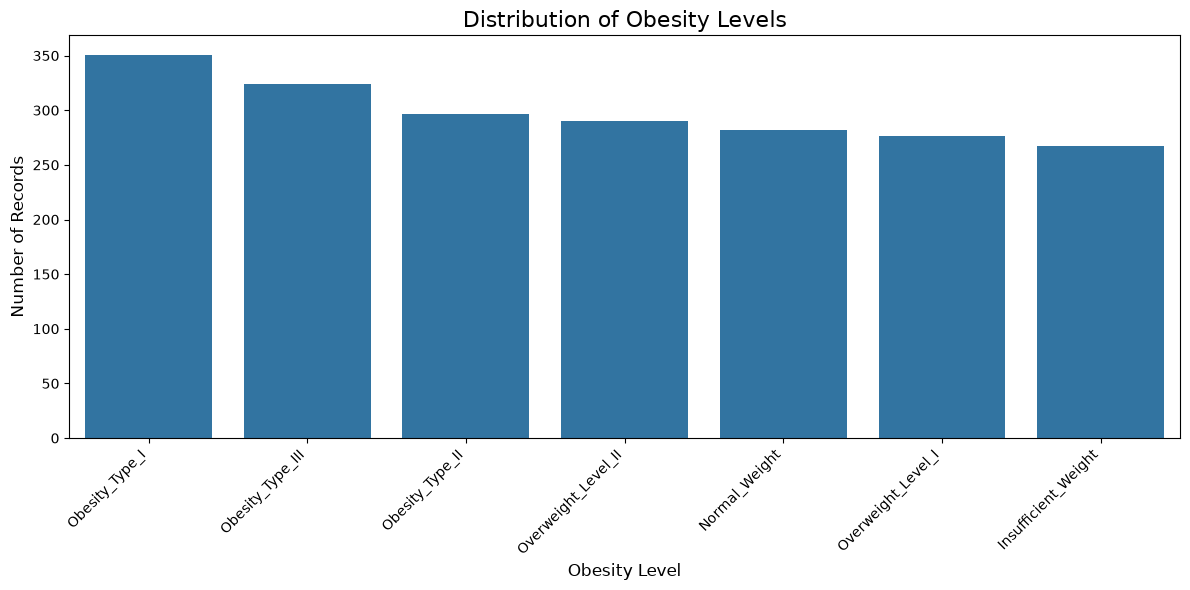

In [43]:
plt.figure(figsize = (12,6))
obesity_order = df["Obesity_level"].value_counts().index

sns.countplot(
    data = df,
    x="Obesity_level",
    order=obesity_order
)
plt.title("Distribution of Obesity Levels",fontsize=16)
plt.xlabel("Obesity Level",fontsize=12)
plt.ylabel("Number of Records",fontsize=12)
plt.xticks(rotation=45,ha="right")
plt.tight_layout()
plt.show()

The bar chart shows the distribution of the seven obesity-level categories across 2,087 records. Obesity Type I has the highest representation, with 351 records, followed by Obesity Type III with 324 records. Insufficient Weight has the lowest representation, with 267 records.

The category counts are relatively balanced, although some obesity levels have more records than others. This distribution allows comparisons between the different weight-status categories during further analysis.

### Distribution of BMI

**Objective:** To examine the distribution of Body Mass Index (BMI) values in the dataset.

I use a histogram with a Kernel Density Estimation (KDE) curve to understand the spread, concentration, and shape of BMI values. This helps identify where BMI values are concentrated and whether the distribution appears symmetric or skewed.

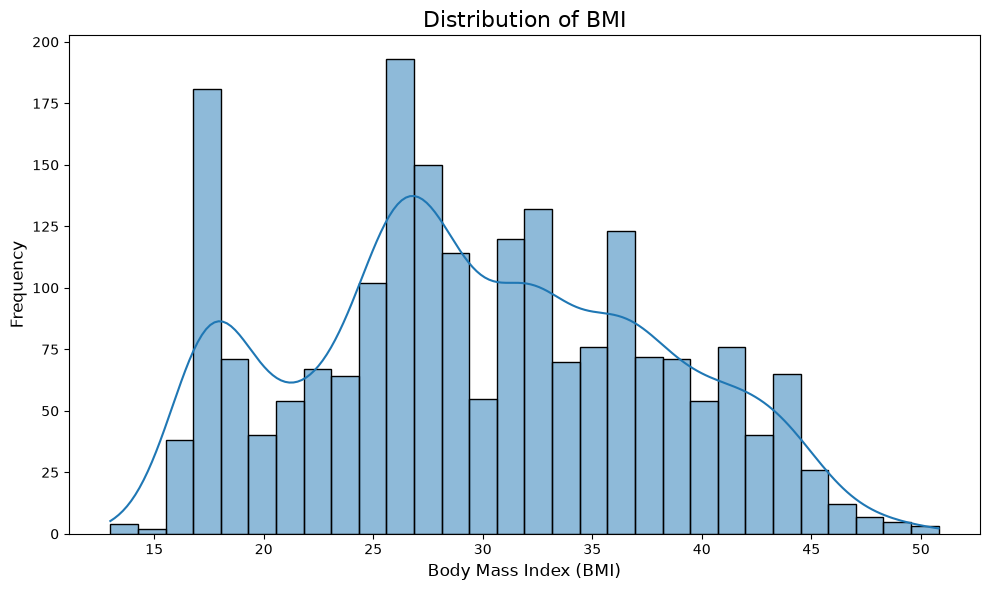

In [44]:
plt.figure(figsize=(10,6))

sns.histplot(
    data = df,
    x = "BMI",
    bins = 30,
    kde = True
)

plt.title("Distribution of BMI",fontsize=16)
plt.xlabel("Body Mass Index (BMI)",fontsize=12)
plt.ylabel("Frequency",fontsize=12)
plt.tight_layout()
plt.show()

The BMI distribution shows values ranging approximately from 13 to 51. The highest concentration of observations appears in the mid-to-high 20s, with another noticeable concentration around BMI 17–18. The distribution is not perfectly symmetric and shows several peaks, suggesting that BMI values may be distributed across multiple clusters.

The frequency gradually decreases at higher BMI values, particularly above approximately 43. These patterns indicate variation in BMI across the dataset and support further comparison of BMI across obesity-level categories.

### Distribution of Age

**Objective:** To understand the age distribution of individuals in the dataset.

I use a histogram with a KDE curve to examine the concentration, spread, and shape of the age distribution. This helps identify the most represented age ranges and determine whether the dataset primarily contains younger or older individuals.

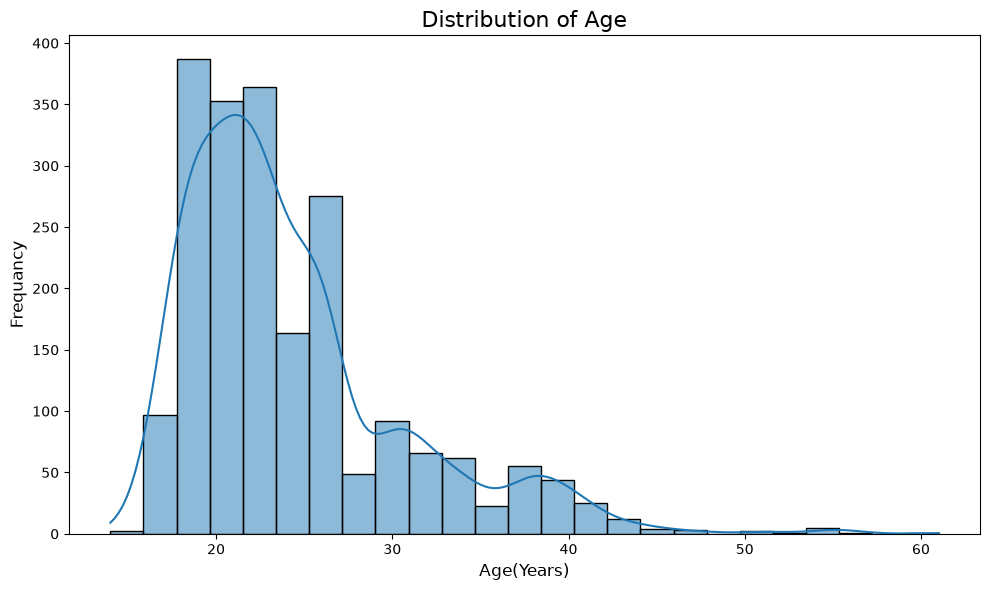

In [45]:
plt.figure(figsize=(10,6))

sns.histplot(
    data = df,
    x = "Age",
    bins = 25,
    kde = True
)

plt.title("Distribution of Age",fontsize =16)
plt.xlabel("Age(Years)",fontsize = 12)
plt.ylabel("Frequancy",fontsize =12)
plt.tight_layout()
plt.show()

The age distribution ranges from approximately 14 to 61 years. Most observations are concentrated between approximately 18 and 27 years, with the highest frequencies occurring in the early twenties.

The distribution is positively skewed, meaning that the majority of observations are concentrated at younger ages, while a smaller number extend toward older ages. Relatively few records represent individuals above 40 years.

This indicates that the dataset is predominantly composed of younger individuals. Therefore, findings from this dataset may not represent age groups equally, and this should be considered when interpreting relationships between age, lifestyle, and obesity level.

### Weight Distribution by Obesity Level

**Objective:** To compare weight distributions across the different obesity-level categories.

I use a box plot to compare the median weight, interquartile range, overall variation, and potential outliers within each category. This helps identify how weight distributions differ across the recorded obesity levels.

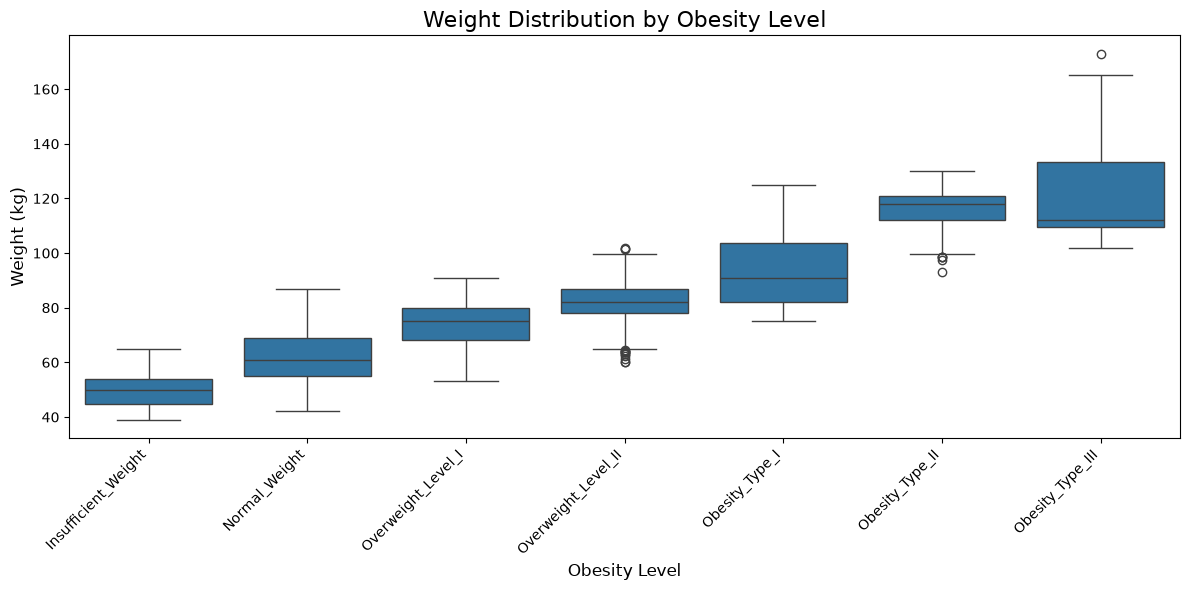

In [46]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="Obesity_level",
    y="Weight",
    order=[
        "Insufficient_Weight",
        "Normal_Weight",
        "Overweight_Level_I",
        "Overweight_Level_II",
        "Obesity_Type_I",
        "Obesity_Type_II",
        "Obesity_Type_III"
    ]
)

plt.title("Weight Distribution by Obesity Level", fontsize=16)
plt.xlabel("Obesity Level", fontsize=12)
plt.ylabel("Weight (kg)", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

The box plot shows differences in weight distributions across the seven obesity-level categories. The median weight generally increases from Insufficient Weight through Normal Weight and the overweight categories, reaching higher values in Obesity Type I and Obesity Type II.

Insufficient Weight has the lowest median weight, at approximately 50 kg. Obesity Type II has a median weight of approximately 118 kg, while Obesity Type III shows a wider spread of weights and includes a high-weight outlier.

Several categories, including Overweight Level II and Obesity Type II, contain potential outliers. These observations indicate variation within the categories and should not automatically be treated as errors.

Overall, weight distributions differ across obesity-level classifications, although weight alone does not explain every difference between individuals.

### BMI Distribution by Obesity Level

**Objective:** To compare BMI values across the different obesity-level categories.

I use a box plot to examine the median BMI, variability, and potential outliers within each obesity-level category. This helps assess how BMI distributions differ across the recorded weight-status classifications.

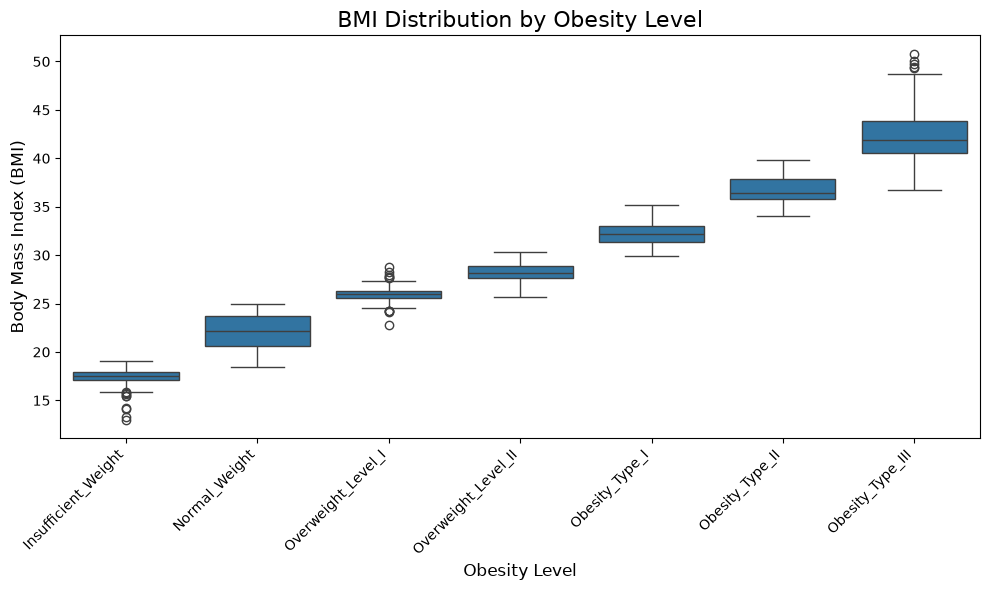

In [47]:
plt.figure(figsize=(10,6))

sns.boxplot(
    data = df,
    x="Obesity_level",
    y="BMI",
    order=[
        "Insufficient_Weight",
        "Normal_Weight",
        "Overweight_Level_I",
        "Overweight_Level_II",
        "Obesity_Type_I",
        "Obesity_Type_II",
        "Obesity_Type_III"
    ]
)

plt.title("BMI Distribution by Obesity Level",fontsize=16)
plt.xlabel("Obesity Level",fontsize=12)
plt.ylabel("Body Mass Index (BMI)",fontsize=12)
plt.xticks(rotation=45,ha="right")
plt.tight_layout()
plt.show()

The box plot shows a clear increase in median BMI across the obesity-level categories. Insufficient Weight has the lowest median BMI, at approximately 17.5, while Obesity Type III has the highest median, at approximately 42.

Normal Weight has a median BMI of around 22, followed by higher median values in the overweight and obesity categories. The distributions are relatively compact within several categories, although some potential outliers are visible, particularly in Insufficient Weight, Overweight Level I, and Obesity Type III.

Overall, BMI values differ substantially across the recorded obesity-level categories. This pattern is expected because obesity-level classifications are related to weight status, so it should be interpreted as a descriptive comparison rather than evidence of causation.

## Physical Activity by Obesity Level

**Objective:** To compare physical activity scores across different obesity-level categories.

I use a box plot to compare the median, variability, and distribution of recorded physical activity scores within each obesity-level category. This helps explore whether activity scores differ between groups in the dataset.

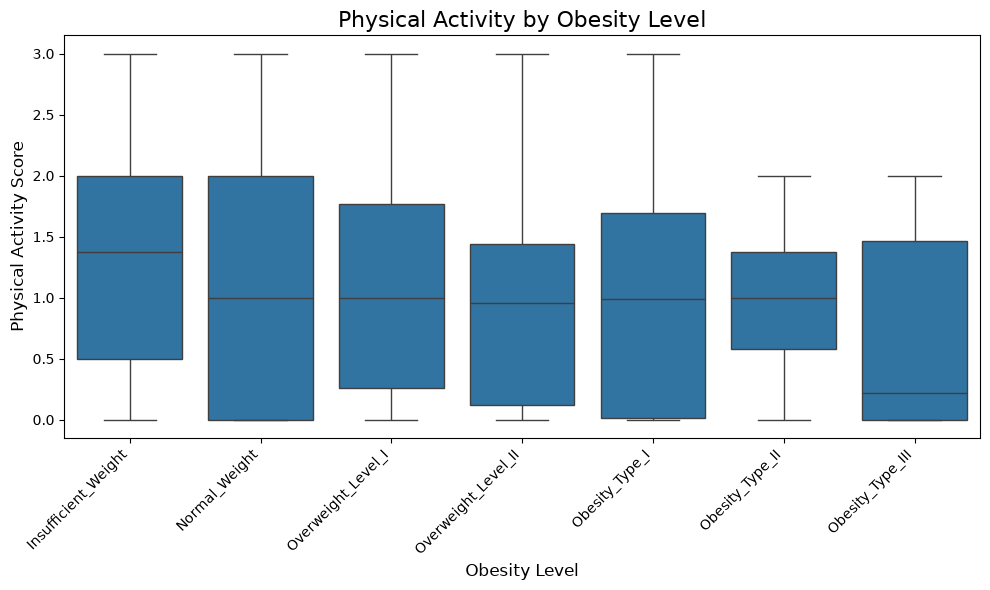

In [48]:
plt.figure(figsize=(10,6))

sns.boxplot(
    data = df,
    x="Obesity_level",
    y="Physical_Activity",
    order=[
        "Insufficient_Weight",
        "Normal_Weight",
        "Overweight_Level_I",
        "Overweight_Level_II",
        "Obesity_Type_I",
        "Obesity_Type_II",
        "Obesity_Type_III"
    ]
)

plt.title("Physical Activity by Obesity Level",fontsize=16)
plt.xlabel("Obesity Level",fontsize=12)
plt.ylabel("Physical Activity Score",fontsize=12)
plt.xticks(rotation=45,ha="right")
plt.tight_layout()
plt.show()

The box plot shows differences in the distribution of physical activity scores across obesity-level categories. Insufficient Weight has a median score of approximately 1.4, while Obesity Type III has a median close to 0.2. The other categories generally have median scores around 1.0.

The spread of activity scores also varies across categories. Insufficient Weight and Normal Weight show relatively broad distributions, while Obesity Type II has a narrower interquartile range. There is considerable overlap between several categories, indicating that activity scores alone do not clearly distinguish every obesity-level group.

Overall, the chart suggests differences in recorded physical activity across the categories. However, this descriptive comparison does not establish that physical activity causes a particular obesity level.

### Obesity Level Distribution by Age Group

**Objective:** To examine how obesity-level categories are distributed across different age groups.

I use a 100% stacked bar chart to compare the percentage distribution of obesity levels within each age group. This allows comparisons between age groups while accounting for differences in the number of records in each group.

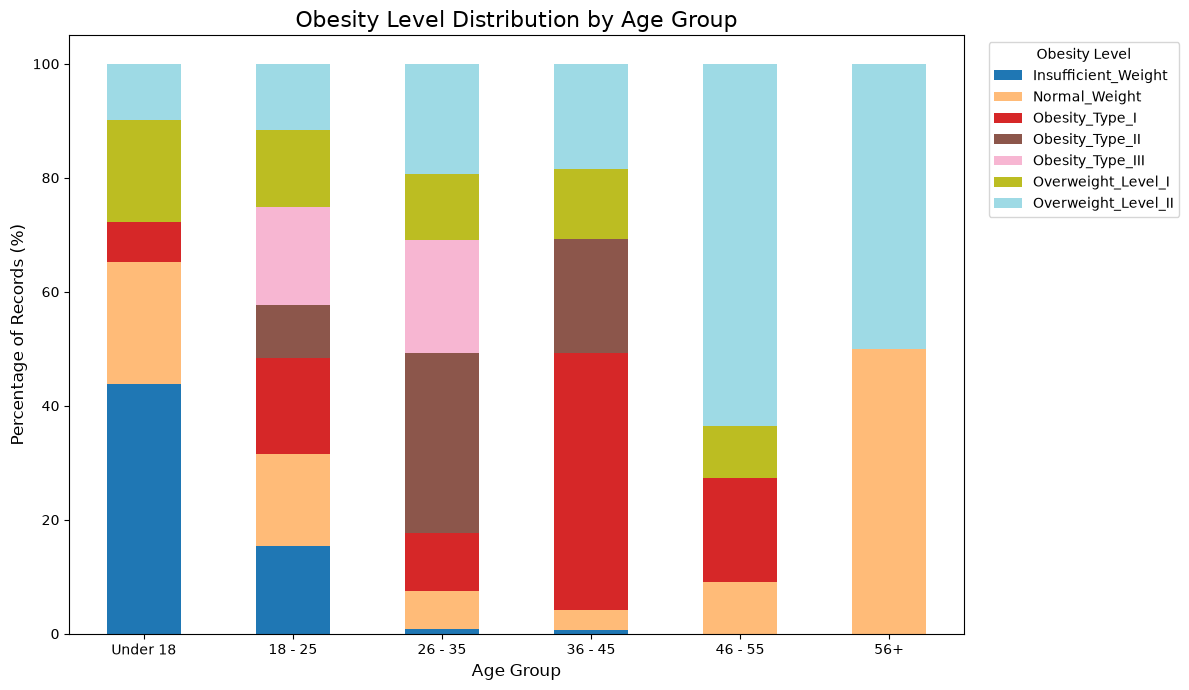

In [49]:
age_obesity_pct = pd.crosstab(
    df["Age_Group"],
    df["Obesity_level"],
    normalize="index"
)*100

age_obesity_pct.plot(
    kind="bar",
    stacked=True,
    figsize=(12,7),
    colormap="tab20"
)
plt.title("Obesity Level Distribution by Age Group",fontsize=16)
plt.xlabel("Age Group",fontsize=12)
plt.ylabel("Percentage of Records (%)",fontsize=12)
plt.xticks(rotation=0)  
plt.legend(
    title="Obesity Level",
    bbox_to_anchor=(1.02,1),
    loc="upper left"
)
plt.tight_layout()
plt.show()

The chart shows differences in the distribution of obesity-level categories across age groups. The Under 18 group has a substantial proportion of records classified as Insufficient Weight and Normal Weight. In the 18–25 age group, the distribution includes several obesity and overweight categories.

The 26–35 and 36–45 age groups show larger proportions of obesity categories, particularly Obesity Type I and Obesity Type II. In the older age groups, the chart shows a different distribution, with Overweight Level II and Normal Weight occupying substantial proportions.

These patterns suggest that the distribution of weight-status classifications varies across age groups in this dataset. However, the chart describes associations rather than proving that age causes differences in obesity levels. The age-group sample sizes should also be considered when interpreting these percentages.

### Correlation Heatmap of Numerical Variables

**Objective:** To examine the strength and direction of linear relationships among numerical variables in the dataset.

I use a correlation heatmap to visualize Pearson correlation coefficients between selected numerical variables. This helps identify positive and negative associations that may be worth investigating further.

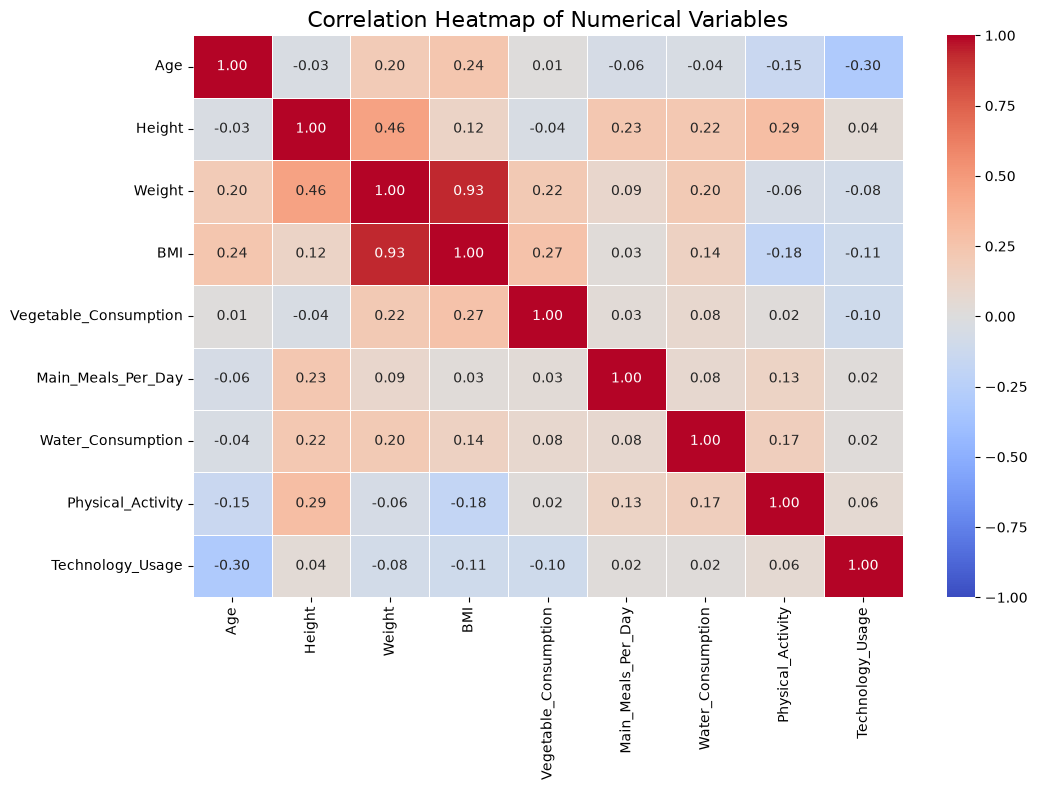

In [50]:
correlation_columns = [
    "Age",
    "Height",
    "Weight",
    "BMI",
    "Vegetable_Consumption",
    "Main_Meals_Per_Day",
    "Water_Consumption",
    "Physical_Activity",
    "Technology_Usage"
]

correlation_matrix = df[correlation_columns].corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Numerical Variables", fontsize=16)
plt.tight_layout()
plt.show()

The correlation heatmap shows the strength and direction of linear relationships between numerical variables in the dataset.

- **Weight and BMI (0.93):** A very strong positive correlation is observed, indicating that higher weight values tend to be associated with higher BMI values. This relationship is partly expected because weight is used to calculate BMI.
- **Height and Weight (0.46):** A moderate positive correlation indicates that taller individuals tend to have higher weights in this dataset.
- **Age and Technology Usage (-0.30):** A moderate negative association suggests that older individuals tend to have lower recorded technology-usage scores.
- **Height and Physical Activity (0.29):** A weak positive association is observed.
- **Age and Physical Activity (-0.15):** A weak negative association is observed.

Most other pairs show relatively weak linear correlations. These results describe associations in the dataset and do not establish causation. The interpretation of lifestyle-related variables should also account for the scales used to record them.

### Interactive Distribution of Obesity Levels

**Objective:** To explore the distribution of obesity-level categories using an interactive bar chart.

I use Plotly to display the number and percentage of records in each obesity-level category. Hover information allows the user to inspect category counts and percentages.

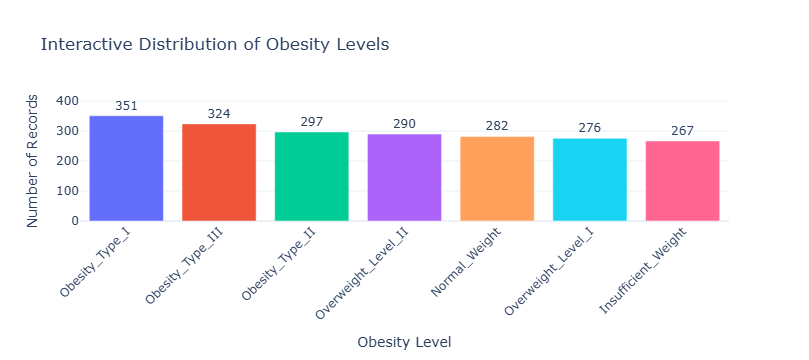

In [64]:
import plotly.express as px

obesity_counts = df["Obesity_level"].value_counts().reset_index()
obesity_counts.columns = ["Obesity_Level", "Count"]

obesity_counts["Percentage"] = (
    obesity_counts["Count"] / len(df) * 100
).round(2)

colors = [
    "#636EFA",
    "#EF553B",
    "#00CC96",
    "#AB63FA",
    "#FFA15A",
    "#19D3F3",
    "#FF6692"
]

fig = px.bar(
    obesity_counts,
    x="Obesity_Level",
    y="Count",
    hover_data=["Percentage"],
    title="Interactive Distribution of Obesity Levels",
    labels={
        "Obesity_Level": "Obesity Level",
        "Count": "Number of Records"
    },
    text="Count",
    color="Obesity_Level",
    color_discrete_sequence=colors
)

fig.update_traces(
    textposition="outside",
    hovertemplate=(
        "<b>%{x}</b><br>"
        "Number of Records: %{y}<br>"
        "Percentage: %{customdata[0]:.2f}%"
        "<extra></extra>"
    )
)

fig.update_layout(
    xaxis_tickangle=-45,
    yaxis_range=[0, obesity_counts["Count"].max() * 1.15],
    template="plotly_white",
    showlegend=False
)

fig.show()

The interactive bar chart shows the distribution of records across the seven obesity-level categories in the dataset, containing 2,087 records after data preprocessing.

Obesity Type I has the highest number of records, with 351 (approximately 16.82%), followed by Obesity Type III with 324 (approximately 15.53%). Insufficient Weight has the lowest representation, with 267 records (approximately 12.79%).

The category counts are relatively balanced, with no single category accounting for a very large proportion of the dataset. The different bar colours make it easier to distinguish the categories, while the interactive hover feature allows users to examine the record counts and percentages.

Overall, the chart provides a clear overview of the distribution of obesity levels and supports comparisons between categories in subsequent analyses.

### Interactive Relationship Between BMI and Weight

**Objective:** To explore the relationship between body weight and Body Mass Index (BMI).

I use an interactive scatter plot to examine how BMI changes with weight. Each point represents a record, and colour indicates the obesity-level category. Hovering over a point provides additional information about the individual record.

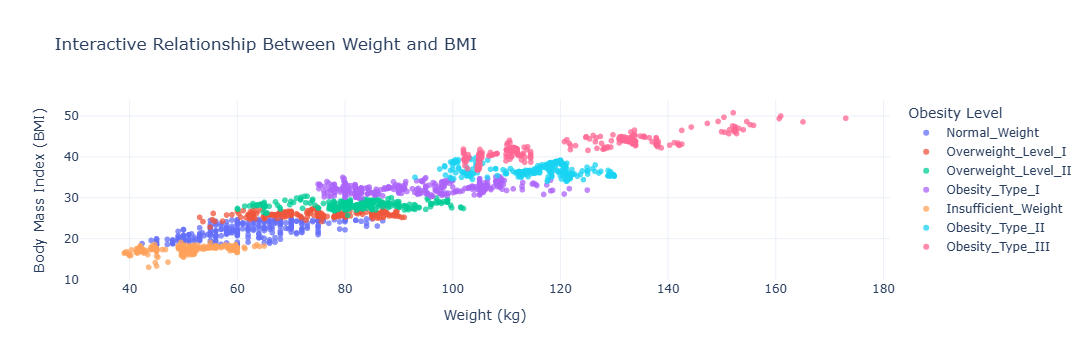

In [67]:
import plotly.express as px

fig = px.scatter(
    df,
    x="Weight",
    y="BMI",
    color="Obesity_level",
    hover_data=["Age", "Height", "Physical_Activity"],
    title="Interactive Relationship Between Weight and BMI",
    labels={
        "Weight": "Weight (kg)",
        "BMI": "Body Mass Index (BMI)",
        "Obesity_level": "Obesity Level"
    },
    opacity=0.75
)

fig.update_layout(
    template="plotly_white",
    legend_title_text="Obesity Level"
)

fig.show()

The interactive scatter plot shows a strong positive relationship between body weight and BMI. As weight increases, BMI generally increases as well, although the exact BMI value also depends on height.

The obesity-level categories form distinguishable clusters. Insufficient Weight records generally appear at lower weight and BMI values, while Obesity Type III records tend to appear at higher values. The other categories occupy intermediate ranges, with some overlap between groups.

This pattern is consistent with the correlation analysis, which showed a strong positive correlation of approximately 0.93 between weight and BMI. Since BMI is calculated using weight and height, this relationship is expected and should not be interpreted as evidence of causation.

### Interactive Lifestyle Comparison by Obesity Level

**Objective:** To explore the relationship between vegetable consumption and physical activity across obesity-level categories.

I use an interactive scatter plot to compare the recorded vegetable-consumption and physical-activity scores. Colour represents obesity level, while hover information displays additional details. This helps explore whether lifestyle-related scores form different patterns across the categories.

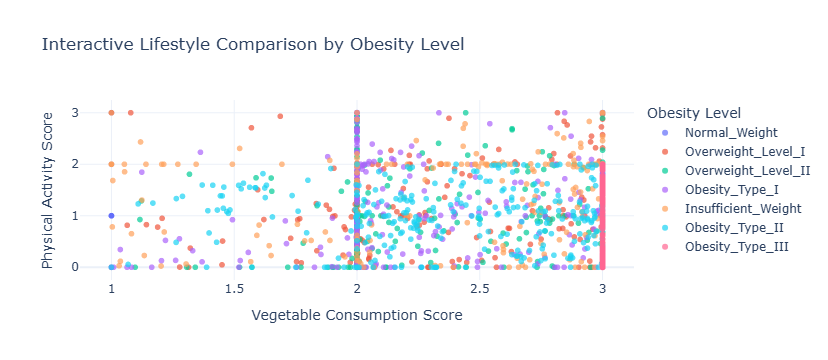

In [69]:
import plotly.express as px

fig = px.scatter(
    df,
    x="Vegetable_Consumption",
    y="Physical_Activity",
    color="Obesity_level",
    hover_data=["Age", "BMI", "Weight"],
    title="Interactive Lifestyle Comparison by Obesity Level",
    labels={
        "Vegetable_Consumption": "Vegetable Consumption Score",
        "Physical_Activity": "Physical Activity Score",
        "Obesity_level": "Obesity Level"
    },
    opacity=0.7
)

fig.update_layout(
    template="plotly_white",
    legend_title_text="Obesity Level"
)

fig.show()

The interactive scatter plot compares vegetable-consumption scores and physical-activity scores across different obesity-level categories. Vegetable-consumption scores range approximately from 1 to 3, while physical-activity scores range from 0 to 3.

The observations are spread across the chart, with many records concentrated around vegetable-consumption scores of 2 to 3. Physical-activity scores also vary considerably within each obesity-level category.

There is substantial overlap between the categories, and no clear separation is visible based on these two variables alone. This suggests that vegetable-consumption and physical-activity scores individually do not clearly distinguish all obesity-level categories in this dataset.

The interactive hover feature allows users to inspect additional information, including age, BMI, and weight, for individual records. These patterns are descriptive and do not establish a causal relationship between lifestyle factors and obesity levels.

### Interactive Multivariate Analysis

**Objective:** To explore the combined relationships between age, BMI, and physical activity across obesity-level categories.

I use an interactive scatter plot to represent age on the x-axis, BMI on the y-axis, and physical activity through marker size. Colour represents obesity level. This allows multiple variables to be explored simultaneously and helps identify patterns and overlaps between categories.

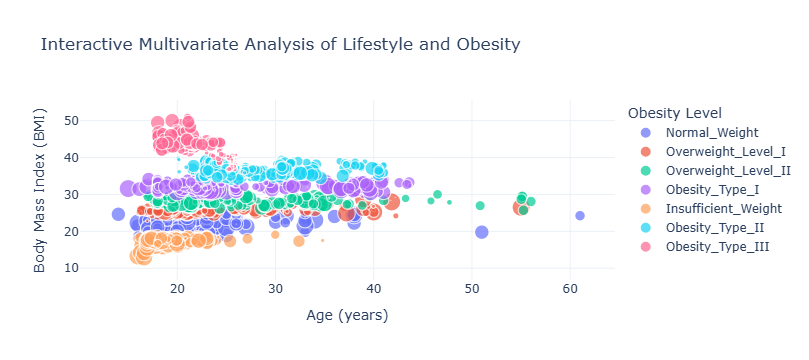

In [71]:
import plotly.express as px

fig=px.scatter(
    df,
    x="Age",
    y="BMI",
    size="Physical_Activity",
    color="Obesity_level",
    hover_data=["Weight","Height","Vegetable_Consumption","Physical_Activity"],
    title="Interactive Multivariate Analysis of Lifestyle and Obesity",
    labels={
        "Age": "Age (years)",
        "BMI": "Body Mass Index (BMI)",
        "Obesity_level": "Obesity Level",
        "Physical_Activity": "Physical Activity Score"
    },
    opacity=0.7,
    size_max=18
)

fig.update_layout(
    template="plotly_white",
    legend_title_text="Obesity Level"
)
fig.show()

The interactive scatter plot examines the relationship between age and BMI, with marker size representing physical activity scores and colour indicating obesity-level categories.

The chart shows that BMI varies across individuals of different ages. The obesity categories form distinguishable clusters based on BMI, although some overlap exists between categories. Obesity Type III records are generally concentrated at higher BMI values, while Insufficient Weight records tend to appear at lower BMI values.

The plot also shows that records within the same age range can have different BMI values and obesity classifications. This indicates that age alone does not fully describe the variation in BMI across the dataset.

The interactive features allow users to inspect individual records and compare their weight, height, vegetable-consumption scores, and physical-activity scores. These patterns describe associations in the dataset and do not establish causation.

## Key Findings

1. **Distribution of obesity levels:** Obesity Type I is the largest category in the cleaned dataset, with 351 records, followed by Obesity Type III with 324 records.

2. **BMI and weight relationship:** Weight and BMI have a strong positive correlation of approximately 0.93. This is expected because body weight is used in the BMI calculation.

3. **Age distribution:** The dataset is concentrated among younger individuals, with the average age approximately 24.35 years. The age distribution is right-skewed, with fewer records at older ages.

4. **Differences in weight and BMI:** The box plots show increasing median weight and BMI across the obesity-level categories, with some overlap and a few potential outliers.

5. **Physical activity patterns:** Physical activity scores vary across obesity-level categories. However, the distributions overlap considerably, so physical activity alone does not clearly distinguish every category.

6. **Age-group comparison:** The proportion of each obesity-level category differs across age groups. These differences describe patterns in the dataset and do not establish a causal relationship between age and obesity.

7. **Lifestyle variables:** Vegetable-consumption and physical-activity scores show considerable variation and overlap across obesity categories. Further analysis would be needed to understand their individual relationships with obesity level.

## Conclusion

The Lifestyle and Obesity Analysis project explored demographic, physical, and lifestyle-related variables to understand patterns associated with obesity levels. The dataset was cleaned by checking missing values, removing duplicate records, standardizing categorical text, and creating derived features such as BMI and age groups.

Exploratory Data Analysis was conducted using descriptive statistics, frequency distributions, group comparisons, correlation analysis, and interactive and non-interactive visualizations. The analysis identified differences in BMI, weight, physical activity scores, and obesity-level distributions across the categories and age groups.

A strong positive correlation was observed between weight and BMI, while the lifestyle-related variables showed more variation and overlap across obesity categories. These findings describe patterns within the dataset and should not be interpreted as proof that a particular lifestyle factor causes obesity.

The analysis demonstrates how data cleaning, statistical summaries, and visualization can help identify meaningful patterns in a health-related dataset. Further investigation using additional variables and appropriate statistical methods could provide a deeper understanding of the relationships between lifestyle, age, and obesity levels.

In [ ]:
ok done 